In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import tensorflow as tf

print("All packages are working!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

All packages are working!
Pandas: 3.0.6
NumPy: 2.5.3
TensorFlow: 2.21.0


UNSW-NB15 DATASET EXPLORATION

1. DATASET SHAPES
Training dataset: (175341, 45)
Testing dataset:  (82332, 45)

2. COLUMN NAMES
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

3. DATA TYPES
id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                  

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0



5. MISSING VALUES
No missing values found.

6. DUPLICATE RECORDS
Training duplicates: 0
Testing duplicates:  0

7. BINARY LABEL DISTRIBUTION
label
1    119341
0     56000
Name: count, dtype: int64

8. ATTACK CATEGORY DISTRIBUTION
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


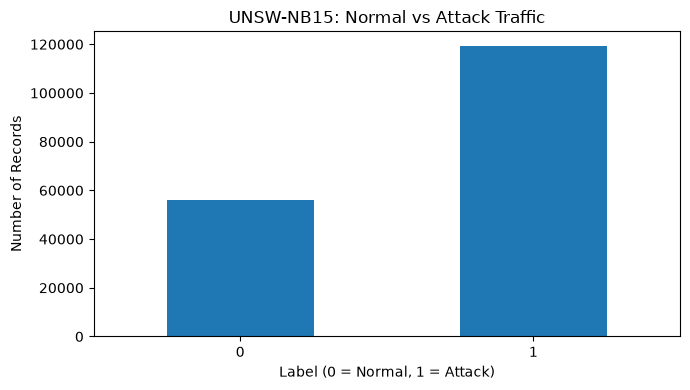

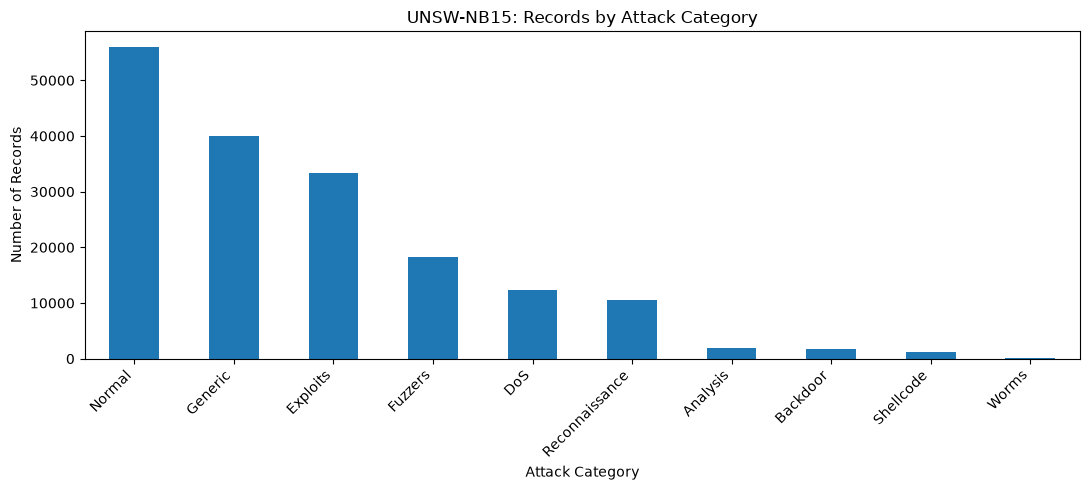


EXPLORATION COMPLETED.


In [9]:

# ============================================================
# UNSW-NB15: Initial Data Exploration
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Locate and load the datasets
DATA_DIR = Path("../data/raw")

training_file = next(DATA_DIR.glob("UNSW_NB15_training-set*.csv"))
testing_file = next(DATA_DIR.glob("UNSW_NB15_testing-set.csv"))

train_df = pd.read_csv(training_file)
test_df = pd.read_csv(testing_file)

print("=" * 60)
print("UNSW-NB15 DATASET EXPLORATION")
print("=" * 60)

# 2. Dataset dimensions
print("\n1. DATASET SHAPES")
print(f"Training dataset: {train_df.shape}")
print(f"Testing dataset:  {test_df.shape}")

# 3. Column names and data types
print("\n2. COLUMN NAMES")
print(train_df.columns.tolist())

print("\n3. DATA TYPES")
print(train_df.dtypes.to_string())

# 4. Preview records
print("\n4. FIRST FIVE TRAINING RECORDS")
display(train_df.head())

# 5. Missing values
print("\n5. MISSING VALUES")
missing = train_df.isnull().sum()
print(missing[missing > 0] if missing.any() else "No missing values found.")

# 6. Duplicate records
print("\n6. DUPLICATE RECORDS")
print(f"Training duplicates: {train_df.duplicated().sum()}")
print(f"Testing duplicates:  {test_df.duplicated().sum()}")

# 7. Target label distributions
print("\n7. BINARY LABEL DISTRIBUTION")
if "label" in train_df.columns:
    print(train_df["label"].value_counts(dropna=False))
else:
    print("The 'label' column was not found.")

print("\n8. ATTACK CATEGORY DISTRIBUTION")
if "attack_cat" in train_df.columns:
    print(train_df["attack_cat"].value_counts(dropna=False))
else:
    print("The 'attack_cat' column was not found.")

# 8. Visualize binary labels
if "label" in train_df.columns:
    train_df["label"].value_counts().sort_index().plot(
        kind="bar", figsize=(7, 4), rot=0
    )
    plt.title("UNSW-NB15: Normal vs Attack Traffic")
    plt.xlabel("Label (0 = Normal, 1 = Attack)")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

# 9. Visualize attack categories
if "attack_cat" in train_df.columns:
    train_df["attack_cat"].value_counts().plot(
        kind="bar", figsize=(11, 5)
    )
    plt.title("UNSW-NB15: Records by Attack Category")
    plt.xlabel("Attack Category")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

print("\nEXPLORATION COMPLETED.")


# UNSW-NB15 Dataset Exploration

## 1. Dataset Overview

The UNSW-NB15 dataset is used for network intrusion detection and contains normal network traffic and multiple categories of cyberattacks.

The downloaded datasets contain 45 columns, including network traffic features, attack categories, and a binary classification label.

## 2. Dataset Dimensions

- Training dataset: 82,332 records and 45 columns.
- Testing dataset: 175,341 records and 45 columns.

The dataset dimensions will be verified before model development because the record counts differ from the commonly distributed UNSW-NB15 training and testing split.

## 3. Data Quality

- No missing values were detected in the training dataset.
- No duplicate rows were detected in either dataset.
- The dataset contains numerical and categorical features.

## 4. Target Variables

The `label` column supports binary classification:
- `0`: Normal traffic
- `1`: Attack traffic

The `attack_cat` column identifies traffic categories, including Normal, Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, and Worms.

## 5. Class Distribution

The training dataset contains 37,000 normal records and 45,332 attack records. The attack categories are imbalanced, with Worms having substantially fewer records than the larger categories.

## 6. Visualizations

Two bar charts were generated to visualize:
1. The distribution of normal and attack traffic.
2. The distribution of records across attack categories.

## 7. Conclusion

The initial exploration identified the dataset structure, target variables, class distribution, and basic data-quality characteristics. Further preprocessing, feature encoding, feature selection, and model evaluation are required before building the intrusion detection system.

In [ ]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data/raw")

for file in data_dir.glob("*.csv"):
    df = pd.read_csv(file)
    print(file.name, "->", df.shape)

In [ ]:
import pandas as pd

train = pd.read_csv("../data/raw/UNSW_NB15_training-set.csv")
test = pd.read_csv("../data/raw/UNSW_NB15_testing-set.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Same columns:", list(train.columns) == list(test.columns))
print("\nTraining categories:")
print(train["attack_cat"].value_counts())
print("\nTesting categories:")
print(test["attack_cat"].value_counts())

In [ ]:
from pathlib import Path

data_dir = Path("../data/raw")

print("Current folder:", Path.cwd())
print("\nFiles inside data/raw:")

for file in data_dir.iterdir():
    print(repr(file.name))

In [ ]:
from pathlib import Path

data_dir = Path("../data/raw")

old_train = data_dir / "UNSW_NB15_training-set.csv.csv"
old_test = data_dir / "UNSW_NB15_testing-set.csv"

print("Training file exists:", old_train.exists())
print("Testing file exists:", old_test.exists())

In [ ]:
from pathlib import Path

data_dir = Path("../data/raw")

print("Files after renaming:")
for file in sorted(data_dir.glob("*.csv")):
    print(file.name)

In [ ]:
import pandas as pd

train = pd.read_csv("../data/raw/UNSW_NB15_training-set.csv")
test = pd.read_csv("../data/raw/UNSW_NB15_testing-set.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Same columns:", list(train.columns) == list(test.columns))

print("\nTraining attack categories:")
print(train["attack_cat"].value_counts())

print("\nTesting attack categories:")
print(test["attack_cat"].value_counts())

In [2]:
import pandas as pd

train = pd.read_csv("../data/raw/UNSW_NB15_training-set.csv")
test = pd.read_csv("../data/raw/UNSW_NB15_testing-set.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print("Same columns:", list(train.columns) == list(test.columns))
print()
print("Missing values (train):", train.isnull().sum().sum())
print("Duplicates (train):", train.duplicated().sum())
print("Duplicates (test) :", test.duplicated().sum())
print()
print("Normal vs attack (train):")
print(train["label"].value_counts())
print()
print("Attack types (train):")
print(train["attack_cat"].value_counts())
print()
print("Attack types (test):")
print(test["attack_cat"].value_counts())
print()
print("Text columns:", train.select_dtypes(include="object").columns.tolist())

Train shape: (175341, 45)
Test shape : (82332, 45)
Same columns: True

Missing values (train): 0
Duplicates (train): 0
Duplicates (test) : 0

Normal vs attack (train):
label
1    119341
0     56000
Name: count, dtype: int64

Attack types (train):
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

Attack types (test):
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64

Text columns: ['proto', 'service', 'state', 'attack_cat']


C:\Users\Admin\AppData\Local\Temp\ipykernel_4184\3257078578.py:23: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("Text columns:", train.select_dtypes(include="object").columns.tolist())
